# Семинар 2. Bag-of-Words, TF-IDF и классификация текста

### План семинара
1. Превратим отзывы в матрицу: Bag-of-Words и n-граммы
2. Посмотрим, как TF-IDF меняет веса слов
3. Обучим классификатор тональности и сравним варианты признаков
4. Разберём ошибки и посмотрим, что использует модель

Работаем с тем же корпусом RuReviews, что и на первом занятии. Теперь будем предсказывать тональность отзыва по тексту.


In [ ]:
%pip install -q "pandas==2.3.3" "scikit-learn==1.6.1" "matplotlib==3.9.4"

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer
from sklearn.preprocessing import normalize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

SEED = 13
LABELS = ["negative", "neutral", "positive"]
COLORS = ["#9b6b80", "#c5a46c", "#598c88"]
pd.set_option("display.max_colwidth", 180)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

## 1. Подготовим данные

Возьмём [RuReviews](https://github.com/sismetanin/rureviews) - отзывы о женской одежде и аксессуарах. Мы помним, в исходном файле 90 тысяч строк и три класса. Метки получены из оценок покупателей: они не всегда однозначно следуют из текста.

Снова прочитаем таблицу через `pd.read_csv`. Файлы первого семинара нам не понадобятся, а то вдруг вы его не делали :)

In [ ]:
url = "https://raw.githubusercontent.com/sismetanin/rureviews/2f6e61d30dc6c58ba47dce72e5803e1f0a3f38a7/women-clothing-accessories.3-class.balanced.csv"
raw = pd.read_csv(url, sep="\t").rename(columns={"review": "text_raw"})
raw.insert(0, "id", raw.index)
raw["label"] = raw["sentiment"].replace({"neautral": "neutral"})
raw.shape

(90000, 4)

Для первого классификатора оставим простую обработку: нижний регистр, `ё -> е` и один пробел вместо нескольких. Исходный отзыв сохраним в `text_raw`. Стоп-слова и окончания пока оставляем: например, «не» может быть полезно для определения тональности.

In [ ]:
def normalize_text(text):
    return re.sub(r"\s+", " ", text.lower().replace("ё", "е")).strip()

nonempty = raw["text_raw"].fillna("").str.strip().ne("")
df = raw.loc[nonempty & raw["label"].isin(LABELS)].copy()
df["text"] = df["text_raw"].map(normalize_text)

На прошлом занятии мы встречали одинаковые формулировки с разными метками. Для этого эксперимента отложим такие группы, а среди остальных повторов оставим по одной записи. Это один из возможных вариантов подготовки учебной выборки: нашу итоговую метрику будем относить именно к ней.

In [ ]:
conflict = df.groupby("text")["label"].transform("nunique").gt(1)
corpus = df.loc[~conflict].drop_duplicates("text").copy()
print("Отложили записей с разными метками одного текста:", int(conflict.sum()))
print("Осталось уникальных текстов:", len(corpus))

Отложили записей с разными метками одного текста: 2885
Осталось уникальных текстов: 85955


Возьмём банч - 30 тысяч отзывов, чтоб эксперименты быстро выполнялись. `stratify` сохраняет примерно те же доли классов.

Разделим их на **train / validation / test** в пропорции **70 / 15 / 15**. На train будем учиться, на validation сравнивать варианты и читать ошибки. Test откроем после выбора модели. Словарь и IDF тоже определяются по train.

Здесь проверяем новые формулировки из того же источника. В данных нет ID товаров и покупателей, поэтому проверить перенос на новые товары или новых авторов таким разбиением нельзя.

In [ ]:
sample, _ = train_test_split(
    corpus, train_size=30_000, stratify=corpus["label"], random_state=SEED
)
train, holdout = train_test_split(
    sample, test_size=0.30, stratify=sample["label"], random_state=SEED
)
valid, test = train_test_split(
    holdout, test_size=0.50, stratify=holdout["label"], random_state=SEED
)

split_counts = pd.DataFrame({
    "train": train["label"].value_counts(),
    "validation": valid["label"].value_counts(),
    "test": test["label"].value_counts(),
}).reindex(LABELS)
split_counts.loc["Всего"] = split_counts.sum()
split_counts

,train,validation,test
label,,,
negative,6976,1495,1495
neutral,6932,1485,1486
positive,7092,1520,1519
Всего,21000,4500,4500


## 2. Bag-of-Words

Но как передать текст обычной модели машинного обучения? Нам нужны числа. Самое простое решение - завести столбец для каждого слова и посчитать, сколько раз оно встретилось в отзыве.

Возьмём три настоящих отзыва из train. Номера строк оставим, чтобы можно было найти их в исходном корпусе.

In [ ]:
demo = train.set_index("id").loc[[75245, 77284, 38918], ["text_raw", "text"]]
with pd.option_context("display.max_colwidth", None):
    display(demo[["text_raw"]])

,text_raw
id,
75245,"Платье хорошее, ткань утеплённая"
77284,"очень хорошее платье, точно в размер, очень красивое летнее платье:))"
38918,"Получила платье и расстроилась. Платье очень короткое, скорее не платье , а туника"


In [ ]:
cnt_vec = CountVectorizer() # bow
demo_counts = cnt_vec.fit_transform(demo["text"])
words = cnt_vec.get_feature_names_out()
counts_table = pd.DataFrame(demo_counts.toarray(), index=demo.index, columns=words)
counts_table

,короткое,красивое,летнее,не,очень,платье,получила,размер,расстроилась,скорее,ткань,точно,туника,утепленная,хорошее
id,,,,,,,,,,,,,,,
75245,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1
77284,0,1,1,0,2,2,0,1,0,0,0,1,0,0,1
38918,1,0,0,1,1,3,1,0,1,1,0,0,1,0,0


`fit_transform` сначала собирает словарь, затем строит матрицу. Строка - отзыв, столбец - слово, значение - число его вхождений.

По умолчанию `CountVectorizer` выделяет последовательности из двух и более букв, цифр или знаков подчёркивания. Пунктуация и одиночная «я» в такую матрицу не попадут.

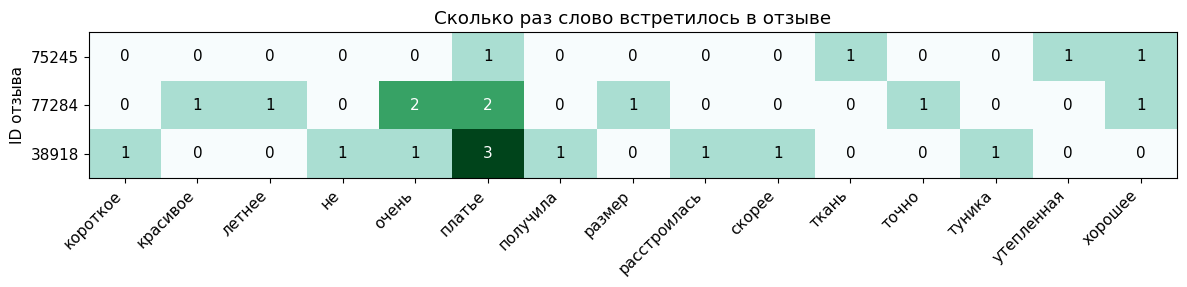

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.imshow(counts_table, cmap="BuGn", vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(len(words)), words, rotation=45, ha="right")
ax.set_yticks(range(len(demo)), demo.index.astype(str))
ax.set_ylabel("ID отзыва")
ax.set_title("Сколько раз слово встретилось в отзыве")
for i in range(len(demo)):
    for j in range(len(words)):
        value = counts_table.iloc[i, j]
        ax.text(j, i, value, ha="center", va="center", color="white" if value >= 2 else "black")
plt.tight_layout()
plt.show()

Большинство слов отсутствует в конкретном тексте. Поэтому sklearn хранит такую матрицу в **разреженном формате**: значения нулевых элементов по отдельности хранить не нужно.

<details>
<summary>Почему в матрице так много нулей?</summary>

В нашей матрице строки соответствуют отзывам, а столбцы - словам из словаря. Словарь собирается по всей обучающей коллекции, но в каждом отдельном отзыве встречается лишь небольшая его часть. Поэтому большинство элементов строки равны нулю.

Матрицу, в которой много нулевых элементов, называют **разреженной**. Это обычная ситуация для Bag-of-Words и TF-IDF: словарь может содержать десятки тысяч признаков, а короткий отзыв использует лишь несколько десятков.

При этом ноль здесь не означает пропущенное значение. В матрице частот он означает, что соответствующее слово не встретилось в тексте при выбранных правилах токенизации.

**Как хранить такую матрицу?**

В **плотном формате** мы храним каждую ячейку, включая все нули. Так устроен обычный двумерный массив NumPy.

В **разреженном формате** достаточно сохранить значения ненулевых элементов и информацию об их расположении. Остальные позиции считаются нулевыми. Значения и размер матрицы сохраняются без потери информации.

Посмотрим на четыре столбца из нашей таблицы:

| ID отзыва | не | очень | платье | туника |
|---|---:|---:|---:|---:|
| 75245 | 0 | 0 | 1 | 0 |
| 77284 | 0 | 2 | 2 | 0 |
| 38918 | 1 | 1 | 3 | 1 |

Здесь всего 12 ячеек, поэтому экономия памяти нам пока не нужна. На этом примере удобно разобраться в устройстве формата.

**CSR: храним матрицу по строкам**

Результат `CountVectorizer` хранится в формате **CSR** - Compressed Sparse Row. В нём используются три массива:

- `data` - сохранённые значения;
- `indices` - номера столбцов, которым соответствуют эти значения;
- `indptr` - границы каждой строки внутри первых двух массивов.

Для нашей маленькой таблицы, если записывать элементы каждой строки по порядку столбцов, получится:

```text
data    = [1, 2, 2, 1, 1, 3, 1]
indices = [2, 1, 2, 0, 1, 2, 3]
indptr  = [0, 1, 3, 7]
```

Нумерация столбцов начинается с нуля: «не» имеет номер 0, «очень» - 1, «платье» - 2, «туника» - 3.

Например, восстановим второй отзыв. Его границы в `indptr` - 1 и 3. Значит, берём срезы:

```text
data[1:3]    = [2, 2]
indices[1:3] = [1, 2]
```

В столбцах 1 и 2 стоят двойки, остальные значения равны нулю. Получаем строку `[0, 2, 2, 0]`.

В `indptr` всегда на один элемент больше, чем строк: нужны начало каждой строки и конечная граница последней.

**Сколько памяти это экономит?**

Оценим масштаб на условной большой коллекции: 100 000 текстов и 50 000 признаков.

Плотная матрица содержит 5 миллиардов ячеек. Если каждое значение занимает 8 байт, как `float64`, только на значения потребуется **40 ГБ**.

Допустим, в каждом тексте в среднем 100 ненулевых признаков. Тогда сохранить нужно 10 миллионов значений. При 8 байтах на значение и 4 байтах на индекс массивы CSR займут примерно **120 МБ**, включая указатели строк.

Это расчёт для выбранных размеров и типов данных, без накладных расходов объектов. Разреженное хранение особенно выгодно, когда ненулевых элементов мало: помимо самих значений нам приходится хранить индексы.

**Почему именно CSR?**

CSR удобно использовать, когда мы часто обращаемся к отдельным строкам или умножаем матрицу на вектор. Для текстовой классификации это естественно: строка соответствует одному документу.

Есть и другие форматы:

| Формат | Как устроен | Для чего удобен |
|---|---|---|
| CSR | Значения сгруппированы по строкам | Обращение к документам, умножение на вектор |
| CSC | Значения сгруппированы по столбцам | Обращение к отдельным признакам |
| COO | Для каждого элемента хранятся строка, столбец и значение | Сборка матрицы из отдельных элементов |

`toarray()` пригодился для трёх отзывов. Для всей коллекции оставляем разреженную матрицу: плотная таблица может занять гораздо больше памяти.

In [ ]:
print("Размер матрицы:", demo_counts.shape)
print("Ненулевых элементов:", demo_counts.nnz)
print("Доля нулей:", round(1 - demo_counts.nnz / np.prod(demo_counts.shape), 3))

Размер матрицы: (3, 15)
Ненулевых элементов: 19
Доля нулей: 0.578


### 2.1 Что считать: слова или сочетания?

Мешок слов не сохраняет порядок. Если в отзыве есть «не подошёл размер», модель видит отдельные признаки «не», «подошел» и «размер».

Биграммы добавляют соседние пары. `ngram_range=(1, 2)` оставит и отдельные слова, и пары; `(2, 2)` - только пары. Посмотрим на отзыв, который уже прочитали.

In [ ]:
example_text = demo.loc[38918, "text"]
print(demo.loc[38918, "text_raw"])
print("\nСлова:", CountVectorizer().build_analyzer()(example_text))
print("\nБиграммы:", CountVectorizer(ngram_range=(2, 2)).build_analyzer()(example_text))

Получила платье и расстроилась. Платье очень короткое, скорее не платье , а туника

Слова: ['получила', 'платье', 'расстроилась', 'платье', 'очень', 'короткое', 'скорее', 'не', 'платье', 'туника']

Биграммы: ['получила платье', 'платье расстроилась', 'расстроилась платье', 'платье очень', 'очень короткое', 'короткое скорее', 'скорее не', 'не платье', 'платье туника']


Соседство здесь определяется после токенизации: пара может пересечь границу предложения. Биграммы сохраняют часть локального порядка, но не всю структуру текста.

**Вопрос:** что добавляет признак «не платье» по сравнению с двумя отдельными словами? Достаточно ли его, чтобы понять весь отзыв?

### 2.2 Как учитывать повторы?

Есть несколько вариантов значений в тех же столбцах:

- **Обычная частота:** сколько раз встретилось слово.
- **Бинарный признак:** встретилось хотя бы один раз или нет.
- **Логарифмический TF:** $1 + \ln(tf)$ для ненулевой частоты. Повторы увеличивают вес, но медленнее. Для отсутствующего слова оставляем 0.

Сравним их для отзыва, где «платье» встретилось три раза.

In [ ]:
demo_id = 38918
demo_position = demo.index.get_loc(demo_id)
row = counts_table.loc[demo_id]
log_tf = TfidfTransformer(use_idf=False, sublinear_tf=True, norm=None)
demo_log_tf = log_tf.fit_transform(demo_counts)

tf_variants = pd.DataFrame({
    "Частота": row,
    "Есть / нет": row.gt(0).astype(int),
    "1 + ln(tf)": demo_log_tf[demo_position].toarray().ravel(),
})
tf_variants.loc[row.gt(0)].round(3)

,Частота,Есть / нет,1 + ln(tf)
короткое,1,1,1.000
не,1,1,1.000
очень,1,1,1.000
платье,3,1,2.099
получила,1,1,1.000
расстроилась,1,1,1.000
скорее,1,1,1.000
туника,1,1,1.000


## 3. TF-IDF

Теперь посмотрим на весь маленький корпус. «Платье» есть во всех трёх отзывах, а «туника» только в одном. Одного подсчёта внутри отзыва недостаточно, чтобы учесть это различие.

**IDF** уменьшает относительный вес слов, которые встречаются во многих документах. В sklearn по умолчанию используется сглаженная формула:

$$\operatorname{IDF}(t) = \ln\frac{1 + N}{1 + df(t)} + 1,$$

где $N$ - число документов, а $df(t)$ - число документов со словом $t$. Три повторения слова в одном отзыве дают вклад **1** в $df$.

Умножим обычную частоту на IDF. Пока отключим нормировку, чтобы увидеть сами произведения. [Описание формулы в sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html).

In [ ]:
idf_transformer = TfidfTransformer(norm=None)
demo_tfidf = idf_transformer.fit_transform(demo_counts)

pd.DataFrame({
    "В скольких отзывах": np.asarray((demo_counts > 0).sum(axis=0)).ravel(),
    "IDF": idf_transformer.idf_,
}, index=words).sort_values("IDF").round(3)

,В скольких отзывах,IDF
платье,3,1.000
очень,2,1.288
хорошее,2,1.288
короткое,1,1.693
красивое,1,1.693
летнее,1,1.693
не,1,1.693
получила,1,1.693
размер,1,1.693
расстроилась,1,1.693


Обычно после этого вектор каждого документа нормируют: при `norm="l2"` сумма квадратов его координат становится равна 1. Это меняет масштаб всего вектора. Пустой вектор остаётся нулевым.

Сравним этапы на одном отзыве. TF-IDF ниже использует обычную частоту; логарифмический TF можно включить отдельно через `sublinear_tf=True`.

In [ ]:
weights_table = tf_variants.copy()
weights_table["TF × IDF"] = demo_tfidf[demo_position].toarray().ravel()
weights_table["TF-IDF после L2"] = normalize(demo_tfidf)[demo_position].toarray().ravel()
weights_table.loc[row.gt(0)].round(3)

,Частота,Есть / нет,1 + ln(tf),TF × IDF,TF-IDF после L2
короткое,1,1,1.000,1.693,0.321
не,1,1,1.000,1.693,0.321
очень,1,1,1.000,1.288,0.244
платье,3,1,2.099,3.000,0.568
получила,1,1,1.000,1.693,0.321
расстроилась,1,1,1.000,1.693,0.321
скорее,1,1,1.000,1.693,0.321
туника,1,1,1.000,1.693,0.321


**Задание 1. Разберём веса**

1. Почему у «платье» IDF меньше, чем у «туника», но TF-IDF до нормировки может оказаться больше?
2. Почему IDF слова, которое есть в каждом документе, здесь равен 1, а не 0?
3. Можно ли по большому TF-IDF понять, что слово указывает на положительный отзыв?

Сначала ответьте по таблицам.

**Дополнительно:** поменяйте `demo_id` на другой ID из `demo` и повторно выполните ячейки с таблицами весов.

При работе с исходными текстами удобно использовать `TfidfVectorizer`: он объединяет подсчёт частот и вычисление TF-IDF.

| Параметр | Что меняет |
|---|---|
| `ngram_range=(1, 2)` | Какие последовательности попадут в признаки |
| `min_df=3` | Оставляет признаки, встречающиеся хотя бы в трёх документах train |
| `max_df=0.95` | Убирает признаки, встречающиеся более чем в 95% документов train |
| `max_features=50_000` | Ограничивает общий словарь слов и n-грамм наиболее частыми признаками; это не отбор по полезности для класса |
| `sublinear_tf=True` | Заменяет ненулевой TF на `1 + ln(tf)` |
| `norm="l2"` | Нормирует каждый вектор документа |

Сначала оставим униграммы и обычный TF. Биграммы проверим отдельным экспериментом.

## 4. Классификация тональности

### 4.1 С чем сравнивать?

Прежде чем обучать модель, проверим совсем простой ответ: всегда предсказывать самый частый класс из train. Результат `DummyClassifier` даст начальную точку для сравнения.

Основная метрика - **macro-F1**: считаем F1 отдельно для каждого класса и берём обычное среднее. Так у каждого из трёх классов одинаковый вес в итоговой оценке.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train["text"], train["label"])
dummy_pred = dummy.predict(valid["text"])
print("Dummy всегда отвечает:", dummy_pred[0])
print("Dummy, macro-F1:", round(f1_score(valid["label"], dummy_pred, average="macro"), 3))

Dummy всегда отвечает: positive
Dummy, macro-F1: 0.168


### 4.2 TF-IDF + логистическая регрессия

Соберём два шага в `Pipeline`. При `fit` векторизатор обучится на train, а классификатор получит готовую матрицу. При `predict` новые тексты преобразуются с тем же словарём и IDF.

`C` управляет силой регуляризации: меньше `C` - сильнее ограничение на веса. `max_iter` задаёт максимум шагов оптимизатора. Пока оставим `C=1` и будем менять только представление текста.

In [ ]:
unigram_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 1), min_df=3, max_df=0.95, max_features=50_000
    )),
    ("clf", LogisticRegression(C=1.0, max_iter=500, random_state=SEED)),
])
unigram_model.fit(train["text"], train["label"])
unigram_pred = unigram_model.predict(valid["text"])
print(classification_report(valid["label"], unigram_pred, labels=LABELS, digits=3))

              precision    recall  f1-score   support

    negative      0.713     0.693     0.703      1495
     neutral      0.604     0.632     0.618      1485
    positive      0.856     0.841     0.848      1520

    accuracy                          0.723      4500
   macro avg      0.724     0.722     0.723      4500
weighted avg      0.725     0.723     0.724      4500



В отчёте **precision** показывает, какая доля предсказаний данного класса оказалась верной. **Recall** - какую долю всех отзывов этого класса модель нашла. `support` - сколько таких отзывов было в validation.

**Вопрос:** какой класс сложнее остальных? Что может означать «нейтральный отзыв» в данных, где метка получена из оценки покупателя?

### 4.3 А если взять биграммы?

Скопируем настройки и изменим только `ngram_range`. Разбиение, ограничения словаря и классификатор сохраняем.

In [ ]:
bigram_model = clone(unigram_model).set_params(tfidf__ngram_range=(1, 2))
bigram_model.fit(train["text"], train["label"])
bigram_pred = bigram_model.predict(valid["text"])

models = {"Униграммы": unigram_model, "Униграммы + биграммы": bigram_model}
valid_predictions = {"Униграммы": unigram_pred, "Униграммы + биграммы": bigram_pred}
comparison = pd.DataFrame({
    "Признаков": {name: len(model["tfidf"].vocabulary_) for name, model in models.items()},
    "Macro-F1 на validation": {
        name: f1_score(valid["label"], valid_predictions[name], average="macro")
        for name in models
    },
})
comparison.round(3)

,Признаков,Macro-F1 на validation
Униграммы,8199,0.723
Униграммы + биграммы,27935,0.735


Новые признаки могут помочь с сочетаниями вроде «не плохое», но без гарантий. Посмотрим на два коротких отзыва: на одном биграммы исправили ответ, на другом добавили ошибку.

In [ ]:
changed = valid.loc[unigram_pred != bigram_pred, ["id", "text_raw", "label"]].copy()
changed["Униграммы"] = unigram_pred[unigram_pred != bigram_pred]
changed["С биграммами"] = bigram_pred[unigram_pred != bigram_pred]
with pd.option_context("display.max_colwidth", None):
    display(changed.loc[changed["id"].isin([80096, 29057])].set_index("id"))

,text_raw,label,Униграммы,С биграммами
id,,,,
29057,"На вид,дешовая клеенка.Запах просто ужасен,пахнут тухлятиной.",negative,negative,positive
80096,доставка 3 недели. платье не плохое. своих денег стоит.,positive,negative,positive


> Что думаете?)

### 4.4 Где модель ошибается?

Выберем вариант с наибольшим macro-F1 на validation. В матрице ошибок строки соответствуют настоящим меткам, столбцы - предсказаниям. Чем больше значений вне диагонали, тем больше путаницы между классами.

Выбран вариант: Униграммы + биграммы


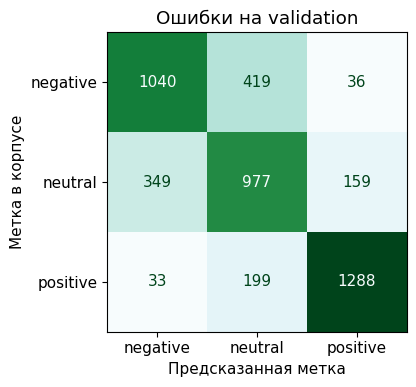

In [ ]:
best_name = comparison["Macro-F1 на validation"].idxmax()
best_model = models[best_name]
valid_pred = valid_predictions[best_name]
print("Выбран вариант:", best_name)

ConfusionMatrixDisplay.from_predictions(
    valid["label"], valid_pred, labels=LABELS,
    cmap="BuGn", colorbar=False, values_format="d"
)
plt.xlabel("Предсказанная метка")
plt.ylabel("Метка в корпусе")
plt.title("Ошибки на validation")
plt.tight_layout()
plt.show()

Прочитаем по одному короткому примеру каждой пары ошибок из матрицы.

In [ ]:
errors = valid.loc[valid["label"].ne(valid_pred), ["id", "text_raw", "label"]].copy()
errors["prediction"] = valid_pred[valid["label"].ne(valid_pred)]
short_errors = errors.loc[errors["text_raw"].str.len().between(25, 180)]
error_examples = short_errors.groupby(["label", "prediction"]).head(1)
with pd.option_context("display.max_colwidth", None):
    display(error_examples.sort_values(["label", "prediction"]).set_index("id"))

,text_raw,label,prediction
id,,,
3262,Очень плохой заказ. Сделано кое-как. Нитки торчат. Шитье пришито неровно. Заказ шел очень долго.,negative,neutral
29057,"На вид,дешовая клеенка.Запах просто ужасен,пахнут тухлятиной.",negative,positive
51007,"пришло очень маленькое ,на меня \r\nне подошло ,заказала м одеть можно только на девушку маленького размера",neutral,negative
45151,"Качество очень понравилось. На параметры 90/65/95 мало, хотя в отзывах видела, что на объём груди 96 см подошло.",neutral,positive
88372,"На вид красивый, на самом деле на подростка лет 14.. Супруга сказала УЖАС...",positive,negative
85987,"запах конечно ужасный, качество вроде норм, мягкая",positive,neutral


**Задание 2. Прочитаем ошибки**

Выберите два отзыва из таблицы и предложите объяснение ошибки. Модель пропустила отрицание? В тексте одновременно есть похвала и жалоба? Или сама метка неожиданна?

Для одного отзыва сформулируйте проверяемую идею улучшения. Например: добавить сочетания определённого типа или изменить токенизацию.

### 4.5 Какие признаки использует модель?

У логистической регрессии есть вес каждого признака для каждого класса. Покажем признаки с наибольшими положительными весами.

Положительный вес увеличивает оценку соответствующего класса при прочих равных. Итоговый ответ зависит от всех признаков отзыва и сравнения оценок трёх классов. Большой коэффициент сам по себе не равен вероятности и не объясняет каждый прогноз.

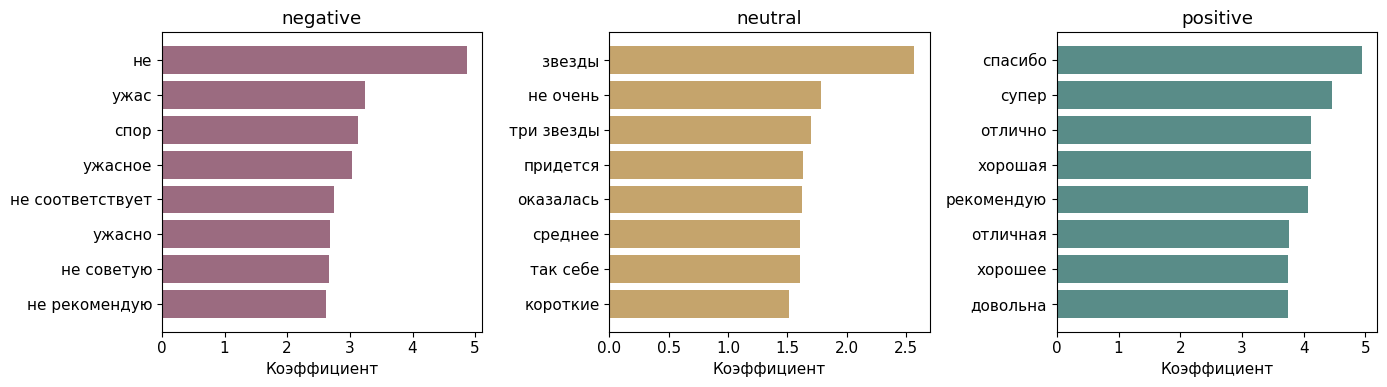

In [ ]:
vectorizer = best_model["tfidf"]
classifier = best_model["clf"]
feature_names = vectorizer.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, label, color in zip(axes, LABELS, COLORS):
    class_index = list(classifier.classes_).index(label)
    weights = classifier.coef_[class_index]
    top = np.argsort(weights)[-8:]
    ax.barh(feature_names[top], weights[top], color=color)
    ax.set_title(label)
    ax.set_xlabel("Коэффициент")
plt.tight_layout()
plt.show()

В нейтральном классе заметны «звезды» и «три звезды». Покупатель может прямо назвать оценку, из которой получена метка. Проверим, насколько полезна эта подсказка сама по себе.

Возьмём правило: если встретилось «три звезды», отвечаем `neutral`. В остальных случаях пока воздерживаемся. Сначала посмотрим на примеры train, затем проверим правило на validation.

In [ ]:
star_pattern = r"\bтри звезды\b"
star_train = train["text"].str.contains(star_pattern, regex=True)
with pd.option_context("display.max_colwidth", None):
    display(train.loc[star_train & train["text_raw"].str.len().lt(180),
                      ["id", "text_raw", "label"]].head(2).set_index("id"))

star_hit = valid["text"].str.contains(star_pattern, regex=True)
star_correct = (star_hit & valid["label"].eq("neutral")).sum()
print(f"Сработало на {star_hit.sum()} отзывах из {len(valid)}; верных ответов: {star_correct}")
print(f"Precision правила: {star_correct / star_hit.sum():.1%}")
print(f"Доля охваченных отзывов: {star_hit.mean():.2%}")
print(f"Recall класса neutral: {star_correct / valid['label'].eq('neutral').sum():.2%}")

,text_raw,label
id,,
39903,"Ставлю три звезды,не могу присоединиться к восторженным отзывам,специфичный фасон,за счёт высокой талии,буду носить дома.",neutral
54137,"Три звезды, что хоть деньги вернули",neutral


Сработало на 8 отзывах из 4500; верных ответов: 8
Precision правила: 100.0%
Доля охваченных отзывов: 0.18%
Recall класса neutral: 0.54%


Правило точно сработало на нескольких примерах, но почти все отзывы оставило без ответа. Precision среди срабатываний и доля охваченных текстов отвечают на разные вопросы.

**Вопрос:** достаточно ли такого правила вместо классификатора? Что произойдёт, если из отзывов исчезнут упоминания звёзд?

Теперь проверим другую сторону представления - что вообще осталось от текста после векторизации? Найдём нулевые векторы на validation.

In [ ]:
valid_vectors = vectorizer.transform(valid["text"])
empty_vectors = valid_vectors.getnnz(axis=1) == 0
print("Нулевых векторов на validation:", int(empty_vectors.sum()))
valid.loc[empty_vectors, ["id", "text_raw", "label"]].head(5)

Нулевых векторов на validation: 11


,id,text_raw,label
75507,75507,супео,positive
11329,11329,Ггггггггг,negative
72728,72728,))),positive
13909,13909,bun elbise gelmedi,negative
41173,41173,Нн,neutral


Так могут потеряться смайлики, одиночные символы или слова вне словаря. Для нулевого вектора у модели остаются только свободные члены.

> Прежде чем усложнять модель, полезно проверить, какую информацию вообще сохранили признаки.

Попробуем символьные n-граммы на двух найденных отзывах. `char_wb` строит последовательности внутри частей текста, разделённых пробелами, и добавляет пробелы по краям. В отличие от словного анализатора он сохраняет и фрагменты слов, и смайлики. Возьмём длины от 3 до 5 символов. Словарь снова обучаем только на train.

In [ ]:
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=50_000)
char_vec.fit(train["text"])
char_demo = valid.set_index("id").loc[[75507, 72728], ["text_raw", "text"]]
char_vectors = char_vec.transform(char_demo["text"])
char_names = char_vec.get_feature_names_out()

char_examples = char_demo[["text_raw"]].copy()
char_examples["Словных признаков"] = vectorizer.transform(char_demo["text"]).getnnz(axis=1)
char_examples["Символьных признаков"] = char_vectors.getnnz(axis=1)
char_examples["Какие признаки сохранились"] = [
    [repr(char_names[j]) for j in char_vectors[i].indices]
    for i in range(len(char_demo))
]
with pd.option_context("display.max_colwidth", None):
    display(char_examples)

,text_raw,Словных признаков,Символьных признаков,Какие признаки сохранились
id,,,,
75507,супео,0,7,"[' су', ' суп', ' супе', 'ео ', 'суп', 'супе', 'упе']"
72728,))),0,6,"[' ))', ' )))', ' ))) ', ')) ', ')))', '))) ']"


У этих двух отзывов появились ненулевые признаки. В «супео» можно сохранить знакомый фрагмент «суп», даже если целого слова нет в словаре. Исправления опечатки при этом не произошло.

Это ещё не доказательство, что символьный классификатор будет лучше. Мы проверили конкретную гипотезу: такое представление сохраняет часть информации, которую словное потеряло.

### 4.6 Итоговая проверка

Вариант выбран по validation. Теперь обучим его заново на train + validation и один раз оценим на test.

В большом эксперименте имеет смысл повторять сравнения на нескольких разбиениях. Здесь ограничимся одним фиксированным разбиением и двумя вариантами признаков.

In [ ]:
train_valid = pd.concat([train, valid])
final_model = clone(best_model)
final_model.fit(train_valid["text"], train_valid["label"])
test_pred = final_model.predict(test["text"])
print("Итоговый вариант:", best_name)
print(classification_report(test["label"], test_pred, labels=LABELS, digits=3))

Итоговый вариант: Униграммы + биграммы
              precision    recall  f1-score   support

    negative      0.732     0.694     0.713      1495
     neutral      0.615     0.671     0.642      1486
    positive      0.876     0.843     0.859      1519

    accuracy                          0.737      4500
   macro avg      0.741     0.736     0.738      4500
weighted avg      0.742     0.737     0.739      4500



## 5. Дополнительные эксперименты

### 5.1 Почему выбран именно этот класс?

В графике выше мы смотрели на коэффициенты модели. Но вклад признака в конкретный отзыв равен **значению признака × коэффициенту**. Отсутствующий признак не вносит вклад, даже если его коэффициент большой.

Вернёмся к отзыву 29057, на котором добавление биграмм испортило ответ. Сравним оценку предсказанного класса с оценкой класса из корпуса. Используем прежнюю модель, обученную только на train.

In [ ]:
example_id = 29057
example = valid.loc[example_id]
x = vectorizer.transform([example["text"]])
predicted_label = best_model.predict([example["text"]])[0]
true_index = list(classifier.classes_).index(example["label"])
pred_index = list(classifier.classes_).index(predicted_label)

contributions = pd.Series(
    x.data * (classifier.coef_[pred_index, x.indices] - classifier.coef_[true_index, x.indices]),
    index=feature_names[x.indices],
)
bias_difference = classifier.intercept_[pred_index] - classifier.intercept_[true_index]

print(example["text_raw"])
print("Метка:", example["label"], "| Предсказание:", predicted_label)
print("Разница свободных членов:", round(bias_difference, 3))
print("Разница оценок с учётом всех признаков:", round(contributions.sum() + bias_difference, 3))
contributions.reindex(contributions.abs().sort_values(ascending=False).head(10).index).to_frame(
    "Вклад в разницу оценок: предсказание минус метка"
).round(3)

На вид,дешовая клеенка.Запах просто ужасен,пахнут тухлятиной.
Метка: negative | Предсказание: positive
Разница свободных членов: 0.294
Разница оценок с учётом всех признаков: 0.248


,Вклад в разницу оценок: предсказание минус метка
клеенка,-0.361
на вид,0.146
запах просто,0.142
просто,-0.111
пахнут,0.108
ужасен,-0.085
вид,0.084
запах,0.082
на,-0.051


**Задание 3. Объясним один прогноз**

Какие признаки склоняют модель к предсказанному классу, а какие - к метке из корпуса? Выберите другой ошибочный отзыв и повторите разбор.

В таблице показаны до десяти наибольших вкладов по модулю. Полная сумма вкладов и разница свободных членов дают разницу оценок двух классов.

### 5.2 А нужен ли здесь IDF?

На маленькой матрице мы видели, как меняются веса. Теперь проверим, помогает ли это классификации. Возьмём униграммный вариант и отключим только IDF: `use_idf=False`.

Так получатся **L2-нормированные частоты**. Это позволит сравнить именно влияние IDF.

Этот дополнительный эксперимент оцениваем только на validation. Итоговую модель основного разбора и её test-оценку оставляем зафиксированными.

In [ ]:
frequency_model = clone(unigram_model).set_params(tfidf__use_idf=False)
frequency_model.fit(train["text"], train["label"])
frequency_pred = frequency_model.predict(valid["text"])

idf_comparison = pd.DataFrame({
    "Признаков": [
        len(frequency_model["tfidf"].vocabulary_), len(unigram_model["tfidf"].vocabulary_)
    ],
    "Macro-F1 на validation": [
        f1_score(valid["label"], frequency_pred, average="macro"),
        f1_score(valid["label"], unigram_pred, average="macro"),
    ],
}, index=["Частоты + L2", "TF-IDF + L2"])
idf_comparison.round(3)

,Признаков,Macro-F1 на validation
Частоты + L2,8199,0.729
TF-IDF + L2,8199,0.723


В этом сравнении нормированные частоты дали немного больший macro-F1, чем TF-IDF. IDF учитывает именно распространённость слова в корпусе. Поэтому улучшение классификации не гарантировано.

**Вопрос:** можно ли из одного разбиения заключить, что IDF здесь вообще не нужен?

Для самостоятельной проверки можно вместо IDF менять `sublinear_tf` или `binary`. Меняйте по одному параметру и сравнивайте варианты на той же validation.

## Что по итогу?

Мы построили классификатор тональности: превратили отзывы в признаки, обучили модель, выбрали вариант по validation и проверили его на test. Оценку качества дополнили разбором конкретных ошибок и проверкой того, какая информация сохранилась при векторизации.

Биграммы помогли на части отзывов, но добавили и новые ошибки. Сильный отдельный признак оказался полезен только для небольшой доли корпуса. Поэтому одной итоговой метрики мало: нужно читать тексты и проверять, за счёт чего модель получает ответ.